# 02 - Feature engineering, model development & experiment tracking

The production training entry point is `python -m heart_risk.train`. This notebook walks through the same building blocks and then inspects the MLflow runs that the script logged.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import pandas as pd, numpy as np
pd.set_option("display.width", 140)

## 1. Preprocessing pipeline

In [2]:
from heart_risk import data, config
from heart_risk.features import build_preprocessor, build_pipeline, transformed_feature_names
df = data.load_clean(); X, y = data.split_xy(df)
pre = build_preprocessor(); pre

Pipeline(steps=[('clinical', ClinicalFeatureBuilder()),
                ('columns',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['age', 'trestbps', 'chol',
                                                   'thalach', 'oldpeak', 'ca',
                                                   'hr_reserve_ratio']),
                                                 ('bin',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='most_frequent'))]),
                                                  ['sex', 'fbs', 'exang']),
                                                 ('cat',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(categories=[[1,
                                                                                              2,
                                                                                              3,
                                                                                              4],
                                                                                             [0,
                                                                                              1,
                                                                                              2],
                                                                                             [1,
                                                                                              2,
                                                                                              3],
                                                                                             [3,
                                                                                              6,
                                                                                              7]],
                                                                                 handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['cp', 'restecg', 'slope',
                                                   'thal'])]))])

In [3]:
Xt = pre.fit_transform(X)
print('raw columns:', X.shape[1], '-> model features:', Xt.shape[1])
cols = pre.named_steps['columns']
print([n.split('__')[1] for n in cols.get_feature_names_out()])

raw columns: 13 -> model features: 23
['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'ca', 'hr_reserve_ratio', 'sex', 'fbs', 'exang', 'cp_1.0', 'cp_2.0', 'cp_3.0', 'cp_4.0', 'restecg_0.0', 'restecg_1.0', 'restecg_2.0', 'slope_1.0', 'slope_2.0', 'slope_3.0', 'thal_3.0', 'thal_6.0', 'thal_7.0']


## 2. Baseline comparison with stratified 5-fold CV
Default hyper-parameters, training split only (80 %, stratified, `random_state=42`).

In [4]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
cv = StratifiedKFold(5, shuffle=True, random_state=42)
rows = {}
for name, est in {'logistic_regression': LogisticRegression(max_iter=5000),
                  'random_forest': RandomForestClassifier(random_state=42),
                  'gradient_boosting': GradientBoostingClassifier(random_state=42)}.items():
    s = cross_validate(build_pipeline(est), X_tr, y_tr, cv=cv,
                       scoring=['accuracy','precision','recall','f1','roc_auc'])
    rows[name] = {k[5:]: v.mean() for k, v in s.items() if k.startswith('test_')}
pd.DataFrame(rows).T.round(4)

,accuracy,precision,recall,f1,roc_auc
logistic_regression,0.8388,0.8769,0.7656,0.8136,0.9069
random_forest,0.8179,0.8242,0.7644,0.7916,0.8925
gradient_boosting,0.8015,0.7986,0.7652,0.7791,0.8629


## 3. Hyper-parameter tuning (what `heart_risk.train` does)
* `GridSearchCV`, 5 stratified folds, refit on **ROC-AUC** (threshold-free, suits a risk score).
* Grids: LR 24 configs (C x penalty x class_weight), RF 24 configs (depth x min_samples_leaf x max_features), GB 16 configs.
* Each configuration is a **nested MLflow run** (params + mean/std CV metrics); each family is a parent run with best params, test metrics, plots and the logged sklearn model.
* Champion = best mean CV ROC-AUC. The test split is only used for the final report, never for selection.

In [5]:
comparison = pd.read_csv(ROOT / 'reports' / 'model_comparison.csv', index_col=0)
comparison

,cv_accuracy,cv_precision,cv_recall,cv_f1,cv_roc_auc,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc,test_avg_precision
family,,,,,,,,,,,
logistic_regression,0.8552,0.8819,0.8008,0.8342,0.9071,0.8689,0.8125,0.9286,0.8667,0.9610,0.9489
random_forest,0.8180,0.8387,0.7644,0.7917,0.9002,0.8852,0.8387,0.9286,0.8814,0.9589,0.9548
gradient_boosting,0.8138,0.8266,0.7644,0.7878,0.8859,0.9016,0.8667,0.9286,0.8966,0.9610,0.9612


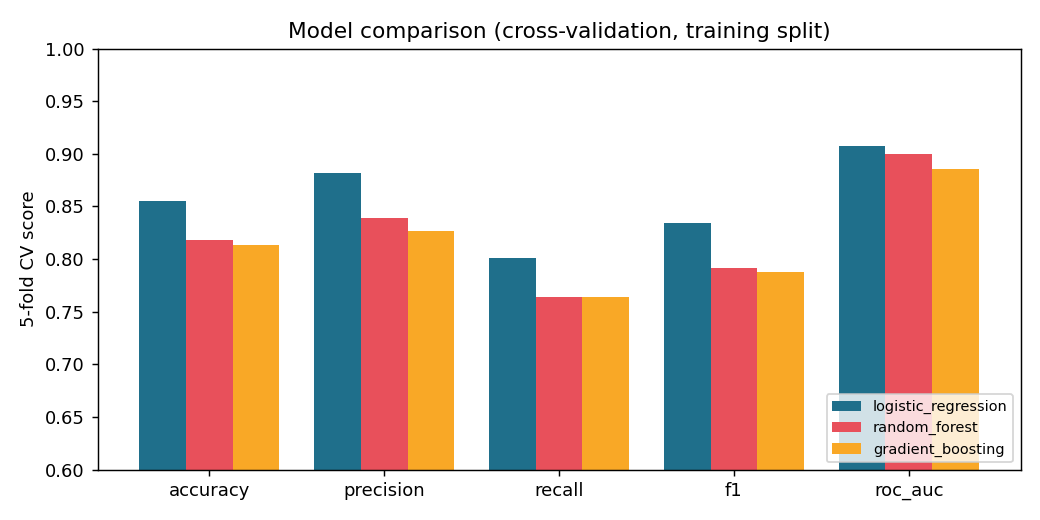

In [6]:
from IPython.display import Image, display
display(Image(filename=str(ROOT / 'reports/figures/model_comparison.png')))

## 4. Experiment tracking - reading the runs back from MLflow

In [7]:
import mlflow
mlflow.set_tracking_uri(config.MLFLOW_TRACKING_URI)
exp = mlflow.get_experiment_by_name(config.MLFLOW_EXPERIMENT)
runs = mlflow.search_runs([exp.experiment_id])
print('total runs:', len(runs), '| nested tuning runs:', runs['tags.mlflow.parentRunId'].notna().sum())
parents = runs[runs['tags.mlflow.parentRunId'].isna() & runs['tags.mlflow.runName'].ne('champion-selection')]
parents[['tags.mlflow.runName','metrics.cv_roc_auc','metrics.test_roc_auc','metrics.test_recall','metrics.test_accuracy']].round(4)

total runs: 68 | nested tuning runs: 64


,tags.mlflow.runName,metrics.cv_roc_auc,metrics.test_roc_auc,metrics.test_recall,metrics.test_accuracy
17,gradient_boosting,0.8859,0.9610,0.9286,0.9016
42,random_forest,0.9002,0.9589,0.9286,0.8852
67,logistic_regression,0.9071,0.9610,0.9286,0.8689


68 runs (64 nested) -> D:\AIML\Sem 3\MLOps\Assignment\heart-disease-mlops\reports\experiment_runs.csv, D:\AIML\Sem 3\MLOps\Assignment\heart-disease-mlops\reports\figures\experiment_tracking_summary.png
                 family  metrics.cv_roc_auc
51  logistic_regression            0.907131
47  logistic_regression            0.906449
49  logistic_regression            0.906115
43  logistic_regression            0.905849
53  logistic_regression            0.905424
45  logistic_regression            0.904816
55  logistic_regression            0.904064
57  logistic_regression            0.903041
44  logistic_regression            0.902754
46  logistic_regression            0.902055



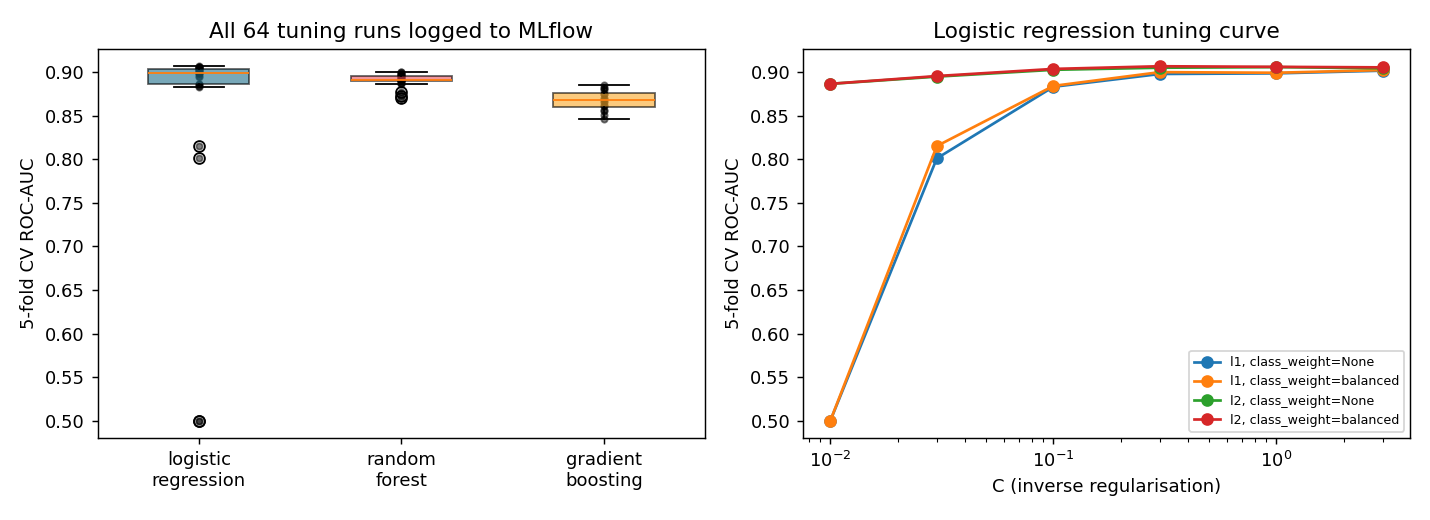

In [8]:
import subprocess
print(subprocess.run([sys.executable, str(ROOT/'scripts/experiment_summary.py')], capture_output=True, text=True).stdout)
display(Image(filename=str(ROOT / 'reports/figures/experiment_tracking_summary.png')))

Observations: strong L1 regularisation (C <= 0.03) wipes out all coefficients (AUC 0.5); from C ~ 0.1 the linear model plateaus at ~0.90-0.91. Tree models do not beat it on this small (242-row) training set - the signal is largely additive, so the simpler, interpretable model wins.

## 5. Champion evaluation on the held-out test split

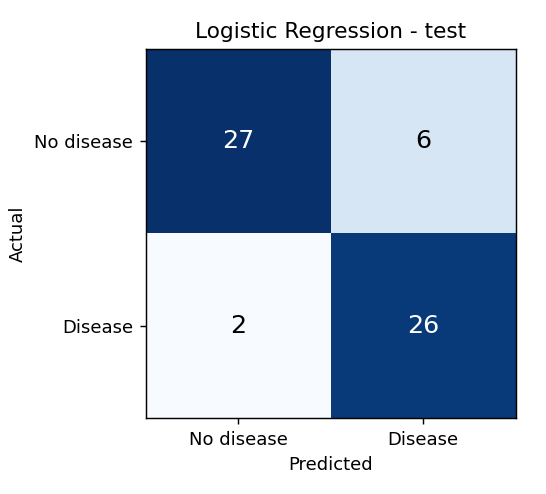

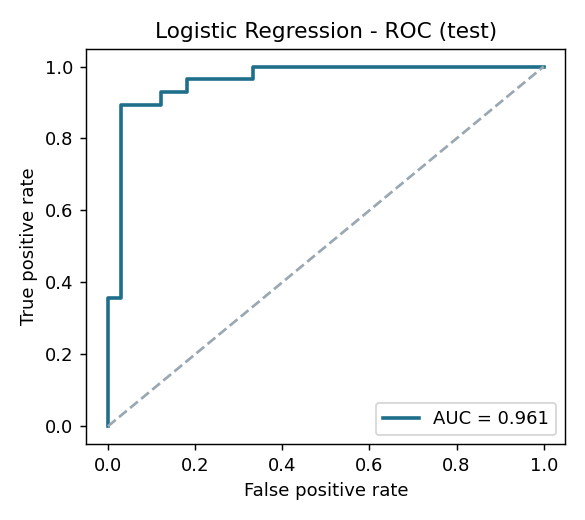

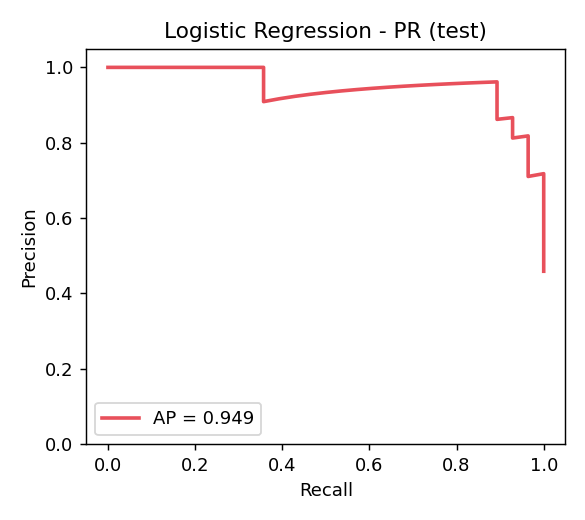

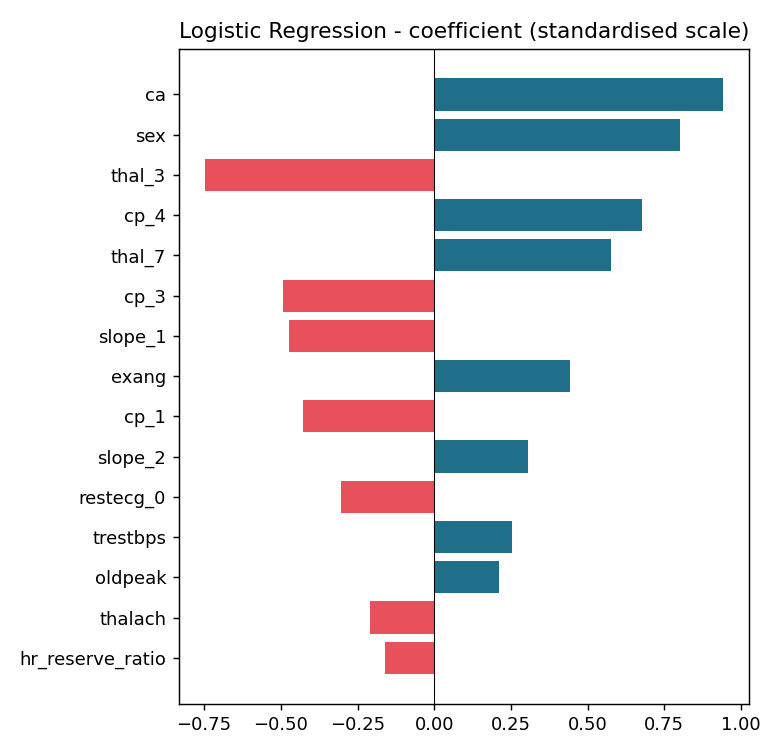

In [9]:
for f in ['confusion_matrix','roc_curve','pr_curve','feature_importance']:
    display(Image(filename=str(ROOT / f'reports/figures/logistic_regression/{f}.png')))

In [10]:
import json
print(json.dumps(json.loads((ROOT/'models/model_metadata.json').read_text()), indent=2))

{
  "model_name": "heart-disease-risk",
  "model_version": "1.0.0",
  "family": "logistic_regression",
  "mlflow_run_id": "cf622ea5215d4130b6631892ae6c7f62",
  "best_params": {
    "C": 0.3,
    "class_weight": "balanced",
    "penalty": "l2"
  },
  "trained_at": "2026-10-19T14:48:29+00:00",
  "features": [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak",
    "ca",
    "sex",
    "fbs",
    "exang",
    "cp",
    "restecg",
    "slope",
    "thal"
  ],
  "decision_threshold": 0.5,
  "n_train": 242,
  "n_test": 61,
  "metrics": {
    "cv_accuracy": 0.8552,
    "cv_precision": 0.8819,
    "cv_recall": 0.8008,
    "cv_f1": 0.8342,
    "cv_roc_auc": 0.9071,
    "test_accuracy": 0.8689,
    "test_precision": 0.8125,
    "test_recall": 0.9286,
    "test_f1": 0.8667,
    "test_roc_auc": 0.961,
    "test_avg_precision": 0.9489
  },
  "quick_mode": false
}
